## Feature Engineering

In [1]:
import numpy as np
import pandas as pd
import re

In [2]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('merged_data_cleaned_v1.csv')

In [4]:
df.duplicated().sum()

np.int64(122)

In [5]:
df.head(3)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up area: 556 sq.ft. (51.65 sq.m.)Carpet area: 500 sq.ft. (46.45 sq.m.),2,2,2,not available,5.0,NaN,1 to 5 Year Old,"['Huda City Centre', 'Golf Course Road', 'Delhi-Mumbai Expressway', 'KMP Expressway', 'Rajiv Chowk', 'IGI Airport']",[],"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']"
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,not available,8.0,West,5 to 10 Year Old,"['Sector metro station', 'Sector metro station', 'Sector 54 chowk metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'Anand Hospital Gurgaon', 'pracksht hospital', 'Arunodaya Deseret Eye Hospital', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'Heera Fuel Station', 'HCG CNG Station', 'Hdfc bank and atm', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Axis bank', 'Icici bank', 'Hdfc bank', 'Hdfc bank & atm', 'Hdfc bank', '222', 'Pizza Hut', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Sagar Ratna', 'IILM', 'Iilm University', 'Sushant College of Arts & Architecture', 'Ansal Institute of Technology', 'Suncity School']","['1 Water Purifier', '7 Fan', '1 Exhaust Fan', '4 Geyser', '15 Light', '1 Chimney', '1 Modular Kitchen', '4 Wardrobe', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']"
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up area: 1700 sq.ft. (157.94 sq.m.)Carpet area: 1500 sq.ft. (139.35 sq.m.),3,3,3+,"pooja room,servant room",17.0,South-East,1 to 5 Year Old,"['Manish Gallexie 91', 'NH-8 IMT Manesar', 'RHM Public School', 'Silver Streak Multi Speciality Hospital', 'Airport', 'Holiday Inn Gurugram']",NaN,"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Swimming Pool', 'Water Storage', 'Park', 'Visitor Parking', 'Fitness Centre / GYM', 'Club house / Community Center']"


In [6]:
# working with areaWithType

df.sample(4)[['price','area','areaWithType']]

,price,area,areaWithType
3567,0.68,1526.0,Built Up area: 1526 (141.77 sq.m.)
1888,1.25,1763.0,Super Built up area 1763(163.79 sq.m.)Built Up area: 1350 sq.ft. (125.42 sq.m.)Carpet area: 1234 sq.ft. (114.64 sq.m.)
1149,2.50,2150.0,Super Built up area 2150(199.74 sq.m.)Carpet area: 1350 sq.ft. (125.42 sq.m.)
2834,1.87,2404.0,Super Built up area 2408(223.71 sq.m.)Built Up area: 2225 sq.ft. (206.71 sq.m.)Carpet area: 2175 sq.ft. (202.06 sq.m.)


In [7]:
# making 3 columns from areaWithType column

In [8]:
# Super Built up area
def get_super_built_up_area(text):
    match = re.search(r'Super Built up area (\d+\.?\d*)', text)
    if match:
        return float(match.group(1))
    return None

In [9]:
# function extracts built up area or carpet area
def get_area(text, area_type):
    match = re.search(area_type + r'\s*:\s*(\d+\.?\d*)', text)
    if match:
        return float(match.group(1))
    return None

In [10]:
# converts measurement into sqft if needed
def convert_to_sqft(text, area_value):
    if area_value is None:
        return None
    match = re.search(r'{} \((\d+\.?\d*) sq.m.\)'.format(area_value), text)
    if match:
        sq_m_value = float(match.group(1))
        return sq_m_value * 10.7639  # conversion factor from sq.m. to sqft
    return area_value

In [11]:
# Extract Super Built up area and convert to sqft if needed
df['super_built_up_area'] = df['areaWithType'].apply(get_super_built_up_area)
df['super_built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['super_built_up_area']), axis=1)

# Extract Built Up area and convert to sqft if needed
df['built_up_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Built Up area'))
df['built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['built_up_area']), axis=1)

# Extract Carpet area and convert to sqft if needed
df['carpet_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Carpet area'))
df['carpet_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['carpet_area']), axis=1)

In [12]:
df[['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].sample(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
2160,1.590,flat,2250.0,Built Up area: 2250 (209.03 sq.m.),NaN,2250.0,NaN
355,0.985,flat,1534.0,Super Built up area 1534(142.51 sq.m.)Carpet area: 1056 sq.ft. (98.11 sq.m.),1534.0,NaN,1056.0
2719,7.000,flat,3850.0,Carpet area: 3850 (357.68 sq.m.),NaN,NaN,3850.0
3110,0.750,flat,1100.0,Built Up area: 1100 (102.19 sq.m.),NaN,1100.0,NaN
785,1.750,flat,2200.0,Super Built up area 2200(204.39 sq.m.)Built Up area: 1900 sq.ft. (176.52 sq.m.)Carpet area: 1700 sq.ft. (157.94 sq.m.),2200.0,1900.0,1700.0


In [13]:
# there is plotarea value at areawithtype column of our houses data 

In [14]:
# rows which have 3 created valid valued columns 'super_built_up_area','built_up_area','carpet_area'
df[~((df['super_built_up_area'].isnull()) | (df['built_up_area'].isnull()) | (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].shape

(534, 7)

In [16]:
# extracting 5 rows which have plotarea and 3 created columns are NaN 
df[df['areaWithType'].str.contains('Plot')][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].head(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
7,9.01,house,5608.0,Plot area 521,NaN,NaN,NaN
16,0.90,house,785.0,Plot area 785(72.93 sq.m.),NaN,NaN,NaN
18,6.30,house,1800.0,Plot area 200(167.23 sq.m.),NaN,NaN,NaN
21,1.60,house,508.0,Plot area 60(50.17 sq.m.),NaN,NaN,NaN
29,13.50,house,3618.0,Plot area 402(336.12 sq.m.),NaN,NaN,NaN


In [17]:

df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    17
price_per_sqft           17
area                     17
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom            0
floorNum                 18
facing                 1102
agePossession             1
nearbyLocations         177
furnishDetails          980
features                633
super_built_up_area    1884
built_up_area          2612
carpet_area            1856
dtype: int64

In [18]:
all_nan_df = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']]

In [19]:
all_nan_df.head()

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
7,9.01,house,5608.0,Plot area 521,NaN,NaN,NaN
16,0.90,house,785.0,Plot area 785(72.93 sq.m.),NaN,NaN,NaN
18,6.30,house,1800.0,Plot area 200(167.23 sq.m.),NaN,NaN,NaN
21,1.60,house,508.0,Plot area 60(50.17 sq.m.),NaN,NaN,NaN
29,13.50,house,3618.0,Plot area 402(336.12 sq.m.),NaN,NaN,NaN


In [20]:
all_nan_index = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].index

In [21]:
# Function to extract plot area from 'areaWithType' column
def extract_plot_area(area_with_type):
    match = re.search(r'Plot area (\d+\.?\d*)', area_with_type)
    return float(match.group(1)) if match else None

In [22]:
# keeping plot area  values at built up area of all_nan_df
all_nan_df['built_up_area'] = all_nan_df['areaWithType'].apply(extract_plot_area)

In [23]:
# sq yard -> sqft we have to do : sqft = 9*sq yard
# sqft = 10.7*sqmt
# here plot area is in yards
def convert_scale(row):
    if np.isnan(row['area']) or np.isnan(row['built_up_area']):
        return row['built_up_area']
    else:
        if round(row['area']/row['built_up_area']) == 9.0:
            return row['built_up_area'] * 9
        elif round(row['area']/row['built_up_area']) == 11.0:
            return row['built_up_area'] * 10.7
        else:
            return row['built_up_area']
all_nan_df['built_up_area'] = all_nan_df.apply(convert_scale,axis=1)

In [24]:
all_nan_df

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
7,9.01,house,5608.0,Plot area 521,NaN,5574.70,NaN
16,0.90,house,785.0,Plot area 785(72.93 sq.m.),NaN,785.00,NaN
18,6.30,house,1800.0,Plot area 200(167.23 sq.m.),NaN,1800.00,NaN
21,1.60,house,508.0,Plot area 60(50.17 sq.m.),NaN,60.00,NaN
29,13.50,house,3618.0,Plot area 402(336.12 sq.m.),NaN,3618.00,NaN
39,1.20,house,900.0,Plot area 900(83.61 sq.m.),NaN,900.00,NaN
52,1.50,house,1170.0,Plot area 130(108.7 sq.m.),NaN,1170.00,NaN
68,2.10,house,900.0,Plot area 100(83.61 sq.m.),NaN,900.00,NaN
72,5.70,house,5400.0,Plot area 600(501.68 sq.m.),NaN,5400.00,NaN
82,4.00,house,981.0,Plot area 109(91.14 sq.m.),NaN,981.00,NaN


In [25]:
df.update(all_nan_df)

In [26]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    17
price_per_sqft           17
area                     17
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom            0
floorNum                 18
facing                 1102
agePossession             1
nearbyLocations         177
furnishDetails          980
features                633
super_built_up_area    1884
built_up_area          2069
carpet_area            1856
dtype: int64

In [27]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up area: 556 sq.ft. (51.65 sq.m.)Carpet area: 500 sq.ft. (46.45 sq.m.),2,2,2,not available,5.0,NaN,1 to 5 Year Old,"['Huda City Centre', 'Golf Course Road', 'Delhi-Mumbai Expressway', 'KMP Expressway', 'Rajiv Chowk', 'IGI Airport']",[],"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",567.0,556.0,500.0
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,not available,8.0,West,5 to 10 Year Old,"['Sector metro station', 'Sector metro station', 'Sector 54 chowk metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'Anand Hospital Gurgaon', 'pracksht hospital', 'Arunodaya Deseret Eye Hospital', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'Heera Fuel Station', 'HCG CNG Station', 'Hdfc bank and atm', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Axis bank', 'Icici bank', 'Hdfc bank', 'Hdfc bank & atm', 'Hdfc bank', '222', 'Pizza Hut', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Sagar Ratna', 'IILM', 'Iilm University', 'Sushant College of Arts & Architecture', 'Ansal Institute of Technology', 'Suncity School']","['1 Water Purifier', '7 Fan', '1 Exhaust Fan', '4 Geyser', '15 Light', '1 Chimney', '1 Modular Kitchen', '4 Wardrobe', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",NaN,NaN,2400.0
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up area: 1700 sq.ft. (157.94 sq.m.)Carpet area: 1500 sq.ft. (139.35 sq.m.),3,3,3+,"pooja room,servant room",17.0,South-East,1 to 5 Year Old,"['Manish Gallexie 91', 'NH-8 IMT Manesar', 'RHM Public School', 'Silver Streak Multi Speciality Hospital', 'Airport', 'Holiday Inn Gurugram']",NaN,"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Swimming Pool', 'Water Storage', 'Park', 'Visitor Parking', 'Fitness Centre / GYM', 'Club house / Community Center']",1930.0,1700.0,1500.0
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up area: 1900 sq.ft. (176.52 sq.m.)Carpet area: 1800 sq.ft. (167.23 sq.m.),3,3,3+,"pooja room,study room,servant room,others",7.0,South,10+ Year Old,"['Sector metro station', 'Sector 54 chowk metro station', 'Sector metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Arunodaya Deseret Eye Hospital', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'pracksht hospital', 'Anand Hospital Gurgaon', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'HCG CNG Station', 'Heera Fuel Station', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Hdfc bank', 'Icici bank', 'Axis bank', 'Hdfc bank & atm', 'Hdfc bank and atm', '222', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Pizza Hut', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Shophouse by Kylin', 'Sagar Ratna', 'Iilm University', 'IILM', 'Sushant College of Arts & Architecture', 'Ansal Institute of Technology', 'Suncity School']",NaN,"['C

In [28]:
# working with additionalRoom
df['additionalRoom'].value_counts

<bound method IndexOpsMixin.value_counts of 0                                       not available
1                                       not available
2                             pooja room,servant room
3           pooja room,study room,servant room,others
4                                       not available
5                                       not available
6                             pooja room,servant room
7                             servant room,store room
8                                          store room
9                                        servant room
10                                      not available
11                                         study room
12                                       servant room
13                                servant room,others
14                                      not available
15                                         study room
16          pooja room,study room,servant room,others
17                                    

In [29]:
df['additionalRoom'].unique()

array(['not available', 'pooja room,servant room',
       'pooja room,study room,servant room,others',
       'servant room,store room', 'store room', 'servant room',
       'study room', 'servant room,others', 'pooja room',
       'store room,servant room', 'others', 'study room,others',
       'study room,pooja room', 'study room,servant room',
       'servant room,pooja room',
       'study room,pooja room,servant room,store room',
       'pooja room,servant room,store room',
       'pooja room,servant room,others',
       'pooja room,study room,servant room', 'servant room,study room',
       'study room,servant room,store room',
       'pooja room,study room,servant room,store room',
       'pooja room,others',
       'pooja room,servant room,study room,store room',
       'pooja room,study room', 'store room,pooja room',
       'servant room,store room,study room,pooja room',
       'store room,pooja room,servant room',
       'pooja room,store room,study room,servant room',
    

In [30]:
unique_rooms = set()

for value in df['additionalRoom'].dropna():
    if value != 'not available':
        rooms = value.split(',')
        unique_rooms.update(room.strip() for room in rooms)

print(sorted(unique_rooms))

['others', 'pooja room', 'servant room', 'store room', 'study room']


In [31]:
rooms = ['pooja room', 'study room', 'servant room',
         'store room', 'others']

for room in rooms:
    column_name = room.replace(' ', '_')

    df[column_name] = df['additionalRoom'].apply(
        lambda x: int(room in [r.strip() for r in x.split(',')])
        if pd.notna(x) and x != 'not available'
        else 0
    )

In [32]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up area: 556 sq.ft. (51.65 sq.m.)Carpet area: 500 sq.ft. (46.45 sq.m.),2,2,2,not available,5.0,NaN,1 to 5 Year Old,"['Huda City Centre', 'Golf Course Road', 'Delhi-Mumbai Expressway', 'KMP Expressway', 'Rajiv Chowk', 'IGI Airport']",[],"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",567.0,556.0,500.0,0,0,0,0,0
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,not available,8.0,West,5 to 10 Year Old,"['Sector metro station', 'Sector metro station', 'Sector 54 chowk metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'Anand Hospital Gurgaon', 'pracksht hospital', 'Arunodaya Deseret Eye Hospital', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'Heera Fuel Station', 'HCG CNG Station', 'Hdfc bank and atm', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Axis bank', 'Icici bank', 'Hdfc bank', 'Hdfc bank & atm', 'Hdfc bank', '222', 'Pizza Hut', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Sagar Ratna', 'IILM', 'Iilm University', 'Sushant College of Arts & Architecture', 'Ansal Institute of Technology', 'Suncity School']","['1 Water Purifier', '7 Fan', '1 Exhaust Fan', '4 Geyser', '15 Light', '1 Chimney', '1 Modular Kitchen', '4 Wardrobe', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",NaN,NaN,2400.0,0,0,0,0,0
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up area: 1700 sq.ft. (157.94 sq.m.)Carpet area: 1500 sq.ft. (139.35 sq.m.),3,3,3+,"pooja room,servant room",17.0,South-East,1 to 5 Year Old,"['Manish Gallexie 91', 'NH-8 IMT Manesar', 'RHM Public School', 'Silver Streak Multi Speciality Hospital', 'Airport', 'Holiday Inn Gurugram']",NaN,"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Swimming Pool', 'Water Storage', 'Park', 'Visitor Parking', 'Fitness Centre / GYM', 'Club house / Community Center']",1930.0,1700.0,1500.0,1,0,1,0,0
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up area: 1900 sq.ft. (176.52 sq.m.)Carpet area: 1800 sq.ft. (167.23 sq.m.),3,3,3+,"pooja room,study room,servant room,others",7.0,South,10+ Year Old,"['Sector metro station', 'Sector 54 chowk metro station', 'Sector metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Arunodaya Deseret Eye Hospital', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'pracksht hospital', 'Anand Hospital Gurgaon', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'HCG CNG Station', 'Heera Fuel Station', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Hdfc bank', 'Icici bank', 'Axis bank', 'Hdfc bank & atm', 'Hdfc bank and atm', '222', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Pizza Hut', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Shophouse by Kylin', 'Sagar Ratna', 'Iilm University', 'IILM', 'Sushant College of

In [33]:
# working with agePossession column
df['agePossession'].value_counts()

agePossession
1 to 5 Year Old       1675
5 to 10 Year Old       574
0 to 1 Year Old        529
undefined              332
10+ Year Old           310
Under Construction      89
Within 6 months         70
Within 3 months         26
Dec-23                  22
By 2023                 19
By 2024                 17
Dec-24                  16
Mar-24                  14
Oct-24                   8
Jan-24                   8
Aug-23                   7
Jun-24                   7
Dec-25                   7
Nov-23                   5
Jul-24                   4
Aug-24                   4
Oct-23                   4
By 2025                  4
Sep-23                   4
Feb-24                   3
Nov-24                   3
Jan-25                   3
May-24                   3
Dec-26                   2
Oct-25                   2
Jul-27                   2
Mar-25                   2
Jun-27                   2
Apr-26                   2
Sep-25                   2
Jan-26                   2
By 2027       

In [34]:
def categorize_age_possession(value):
    if pd.isna(value):
        return "Undefined"
    if "0 to 1 Year Old" in value or "Within 6 months" in value or "Within 3 months" in value:
        return "New Property"
    if "1 to 5 Year Old" in value:
        return "Relatively New"
    if "5 to 10 Year Old" in value:
        return "Moderately Old"
    if "10+ Year Old" in value:
        return "Old Property"
    if "Under Construction" in value or "By" in value:
        return "Under Construction"
    try:
        # For entries like 'May 2024'
        int(value.split(" ")[-1])
        return "Under Construction"
    except:
        return "Undefined"

In [35]:
df['agePossession'] = df['agePossession'].apply(categorize_age_possession)

In [36]:
df['agePossession'].value_counts()

agePossession
Relatively New        1675
New Property           625
Moderately Old         574
Undefined              484
Old Property           310
Under Construction     131
Name: count, dtype: int64

In [37]:
df.head(5)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up area: 556 sq.ft. (51.65 sq.m.)Carpet area: 500 sq.ft. (46.45 sq.m.),2,2,2,not available,5.0,NaN,Relatively New,"['Huda City Centre', 'Golf Course Road', 'Delhi-Mumbai Expressway', 'KMP Expressway', 'Rajiv Chowk', 'IGI Airport']",[],"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",567.0,556.0,500.0,0,0,0,0,0
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,not available,8.0,West,Moderately Old,"['Sector metro station', 'Sector metro station', 'Sector 54 chowk metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'Anand Hospital Gurgaon', 'pracksht hospital', 'Arunodaya Deseret Eye Hospital', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'Heera Fuel Station', 'HCG CNG Station', 'Hdfc bank and atm', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Axis bank', 'Icici bank', 'Hdfc bank', 'Hdfc bank & atm', 'Hdfc bank', '222', 'Pizza Hut', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Sagar Ratna', 'IILM', 'Iilm University', 'Sushant College of Arts & Architecture', 'Ansal Institute of Technology', 'Suncity School']","['1 Water Purifier', '7 Fan', '1 Exhaust Fan', '4 Geyser', '15 Light', '1 Chimney', '1 Modular Kitchen', '4 Wardrobe', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",NaN,NaN,2400.0,0,0,0,0,0
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up area: 1700 sq.ft. (157.94 sq.m.)Carpet area: 1500 sq.ft. (139.35 sq.m.),3,3,3+,"pooja room,servant room",17.0,South-East,Relatively New,"['Manish Gallexie 91', 'NH-8 IMT Manesar', 'RHM Public School', 'Silver Streak Multi Speciality Hospital', 'Airport', 'Holiday Inn Gurugram']",NaN,"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Swimming Pool', 'Water Storage', 'Park', 'Visitor Parking', 'Fitness Centre / GYM', 'Club house / Community Center']",1930.0,1700.0,1500.0,1,0,1,0,0
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up area: 1900 sq.ft. (176.52 sq.m.)Carpet area: 1800 sq.ft. (167.23 sq.m.),3,3,3+,"pooja room,study room,servant room,others",7.0,South,Old Property,"['Sector metro station', 'Sector 54 chowk metro station', 'Sector metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Arunodaya Deseret Eye Hospital', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'pracksht hospital', 'Anand Hospital Gurgaon', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'HCG CNG Station', 'Heera Fuel Station', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Hdfc bank', 'Icici bank', 'Axis bank', 'Hdfc bank & atm', 'Hdfc bank and atm', '222', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Pizza Hut', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Shophouse by Kylin', 'Sagar Ratna', 'Iilm University', 'IILM', 'Sushant College of Art

In [38]:
# working with furnishDetails
df.sample(5)[['furnishDetails','features']]

,furnishDetails,features
2419,"['3 Light', '6 AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Shopping Centre', 'Fitness Centre / GYM', 'Rain Water Harvesting', 'Club house / Community Center', 'Water softening plant']"
1323,[],"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Swimming Pool', 'Water Storage', 'Park', 'Visitor Parking', 'Shopping Centre', 'Fitness Centre / GYM', 'Club house / Community Center']"
1533,"['2 Wardrobe', '4 Fan', '1 Exhaust Fan', '2 Geyser', '8 Light', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Centrally Air Conditioned', 'Water purifier', 'Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Piped-gas', 'Internet/wi-fi connectivity', 'Recently Renovated', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Low Density Society', 'Waste Disposal', 'Rain Water Harvesting', 'Water softening plant', 'Shopping Centre', 'Fitness Centre / GYM', 'Club house / Community Center']"
601,NaN,"['Water purifier', 'Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'No open drainage around', 'Piped-gas', 'Internet/wi-fi connectivity', 'Recently Renovated', 'Visitor Parking', 'Swimming Pool', 'Park', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Low Density Society', 'Waste Disposal', 'Rain Water Harvesting', 'Water softening plant', 'Shopping Centre', 'Fitness Centre / GYM', 'Club house / Community Center']"
746,[],"['Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking', 'Waste Disposal', 'Rain Water Harvesting']"


In [40]:
# Extract all unique furnishings from the furnishDetails column
all_furnishings = []
for detail in df['furnishDetails'].dropna():
    furnishings = detail.replace('[', '').replace(']', '').replace("'", "").split(', ')
    all_furnishings.extend(furnishings)
unique_furnishings = list(set(all_furnishings))

In [41]:
# function to extract the count of a furnishing from the furnishDetails
def get_furnishing_count(details, furnishing):
    if isinstance(details, str):
        if f"No {furnishing}" in details:
            return 0
        pattern = re.compile(f"(\d+) {furnishing}")
        match = pattern.search(details)
        if match:
            return int(match.group(1))
        elif furnishing in details:
            return 1
    return 0

In [42]:
# Simplify the furnishings list by removing "No" prefix and numbers
columns_to_include = [re.sub(r'No |\d+', '', furnishing).strip() for furnishing in unique_furnishings]
columns_to_include = list(set(columns_to_include))  # Get unique furnishings
columns_to_include = [furnishing for furnishing in columns_to_include if furnishing]  # Remove empty strings

# Create new columns for each unique furnishing and populate with counts
for furnishing in columns_to_include:
    df[furnishing] = df['furnishDetails'].apply(lambda x: get_furnishing_count(x, furnishing))

# Create the new dataframe with the required columns
furnishings_df = df[['furnishDetails'] + columns_to_include]

In [43]:
# Create new columns for each unique furnishing and populate with counts
for furnishing in columns_to_include:
    df[furnishing] = df['furnishDetails'].apply(lambda x: get_furnishing_count(x, furnishing))

# Create the new dataframe with the required columns
furnishings_df = df[['furnishDetails'] + columns_to_include]

In [44]:
furnishings_df.shape

(3799, 19)

In [45]:
furnishings_df.sample(7)

,furnishDetails,TV,Water Purifier,Washing Machine,Light,AC,Sofa,Exhaust Fan,Wardrobe,Bed,Stove,Curtains,Chimney,Microwave,Fridge,Geyser,Fan,Dining Table,Modular Kitchen
2964,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1377,"['1 Fan', '1 Light', '1 Modular Kitchen', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1
1012,"['5 Fan', '1 Exhaust Fan', '5 Geyser', '14 Light', '1 Modular Kitchen', '1 Chimney', '6 Wardrobe', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']",0,0,0,14,0,0,1,6,0,0,0,1,0,0,5,5,0,1
3693,"['1 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2106,"['1 Exhaust Fan', '1 Stove', '4 Light', '4 AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0,0,0,4,4,0,1,0,0,1,0,0,0,0,0,0,0,0
213,"['8 Fan', '1 Exhaust Fan', '5 Geyser', '13 Light', '5 AC', '1 Chimney', '1 Curtains', '1 Modular Kitchen', '4 Wardrobe', 'No Bed', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']",0,0,0,13,5,0,1,4,0,0,1,1,0,0,5,8,0,1
214,"['5 Wardrobe', '1 Stove', '1 Microwave', '20 Light', '10 AC', '1 Chimney', '1 Modular Kitchen', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Fridge', 'No Sofa', 'No TV', 'No Washing Machine', 'No Water Purifier']",0,0,0,20,10,0,0,5,0,1,0,1,1,0,0,0,0,1


In [46]:
furnishings_df.drop(columns=['furnishDetails'],inplace=True)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_50600\114705885.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  furnishings_df.drop(columns=['furnishDetails'],inplace=True)


In [47]:
furnishings_df.sample(5)

,TV,Water Purifier,Washing Machine,Light,AC,Sofa,Exhaust Fan,Wardrobe,Bed,Stove,Curtains,Chimney,Microwave,Fridge,Geyser,Fan,Dining Table,Modular Kitchen
98,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2471,0,0,0,15,0,0,1,6,0,0,0,0,0,0,4,6,0,1
566,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2946,0,0,0,10,0,0,0,4,0,0,0,0,0,0,0,6,0,1
1925,0,1,0,36,12,0,1,7,0,1,1,1,1,1,12,9,0,1


In [52]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [53]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(furnishings_df)

In [54]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(scaled_data)
    wcss_reduced.append(kmeans.inertia_)

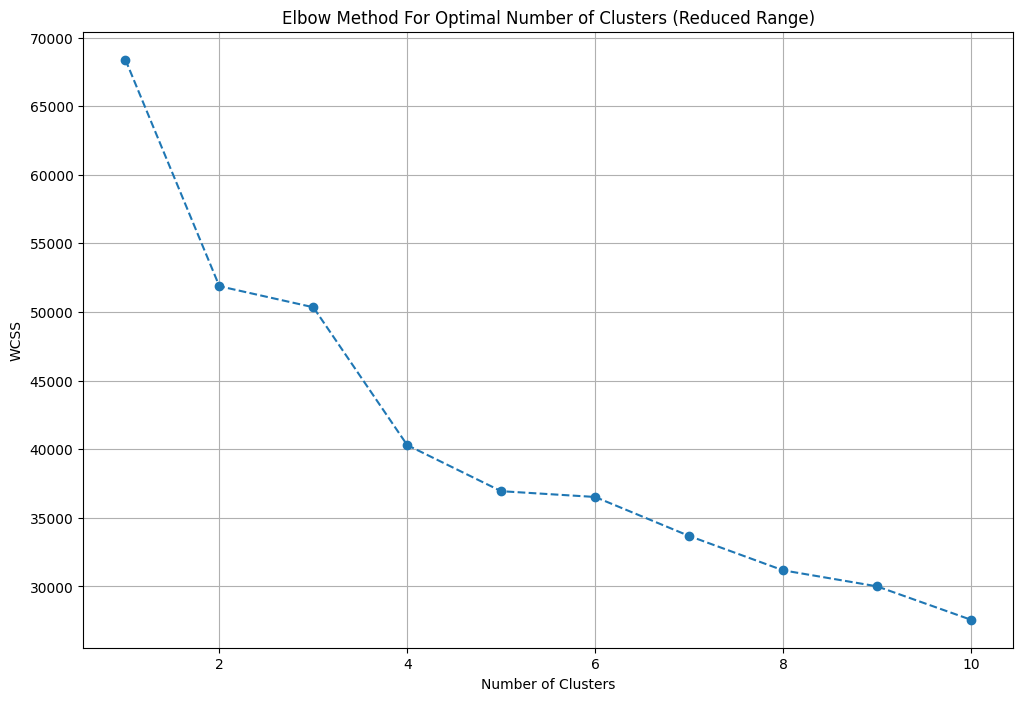

In [55]:
# Ploting the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [56]:
# PCA visualization of cluster 3 and 4
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

furnishings_df_pca = pca.fit_transform(furnishings_df)

print("Explained Variance:", pca.explained_variance_ratio_)
print("Total Variance:", pca.explained_variance_ratio_.sum())

Explained Variance: [0.84301856 0.07790988]
Total Variance: 0.9209284387790062


In [58]:
from sklearn.cluster import KMeans

# 3 clusters
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(furnishings_df)

# 4 clusters
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_4 = kmeans_4.fit_predict(furnishings_df)

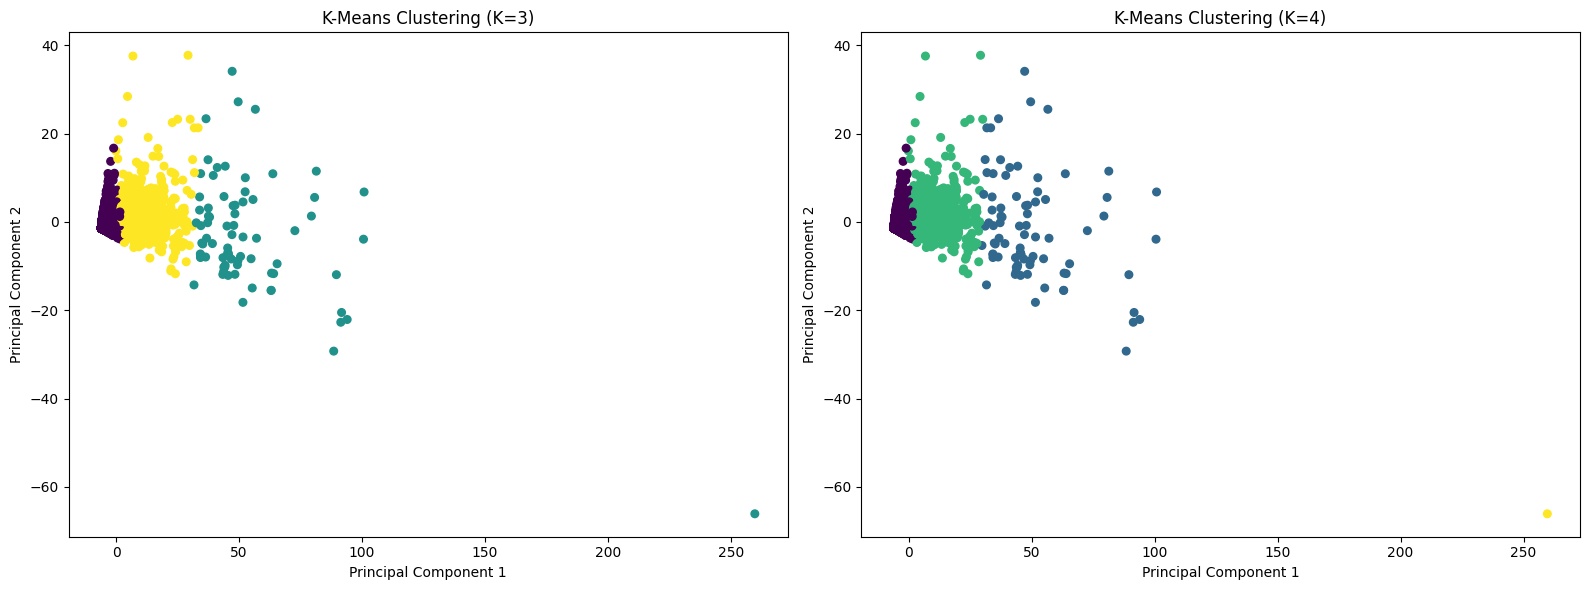

In [59]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K = 3
axes[0].scatter(
    furnishings_df_pca[:, 0],
    furnishings_df_pca[:, 1],
    c=labels_3,
    cmap='viridis',
    s=30
)

axes[0].set_title('K-Means Clustering (K=3)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# K = 4
axes[1].scatter(
    furnishings_df_pca[:, 0],
    furnishings_df_pca[:, 1],
    c=labels_4,
    cmap='viridis',
    s=30
)

axes[1].set_title('K-Means Clustering (K=4)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

In [60]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

for k, labels in [(3, labels_3), (4, labels_4)]:

    print(f"\nK = {k}")
    print("Silhouette Score:",
          silhouette_score(furnishings_df, labels))

    print("Davies-Bouldin Score:",
          davies_bouldin_score(furnishings_df, labels))

    print("Cluster Sizes:",
          pd.Series(labels).value_counts().sort_index().to_dict())


K = 3
Silhouette Score: 0.620846178490193
Davies-Bouldin Score: 0.7101835378518825
Cluster Sizes: {0: 2739, 1: 77, 2: 983}

K = 4
Silhouette Score: 0.6210042435699579
Davies-Bouldin Score: 0.553520482387934
Cluster Sizes: {0: 2727, 1: 83, 2: 988, 3: 1}


In [61]:
# so we choose cluster k = 3 

In [62]:
n_clusters = 3

# Fit the KMeans model
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(scaled_data)

# Predict the cluster assignments for each row
cluster_assignments = kmeans.predict(scaled_data)

In [63]:
df = df.iloc[:,:-18]

In [64]:
df['furnishing_type'] = cluster_assignments

In [70]:
df.sample(5)[['furnishDetails','furnishing_type']]
# 0 -> unfurnished
# 1 -> semifurnished
# 2 -> furnished

,furnishDetails,furnishing_type
866,"['1 Wardrobe', '1 Fan', '1 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']",0
3555,[],0
2570,"['3 Wardrobe', '5 Fan', '1 Exhaust Fan', '15 Light', '5 AC', '1 Modular Kitchen', '1 Chimney', 'No Bed', 'No Curtains', 'No Dining Table', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']",0
2616,"['5 Fan', '2 Geyser', '7 Light', '2 Wardrobe', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']",0
3282,"['6 Fan', '1 Exhaust Fan', '1 Geyser', '5 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0


In [66]:
# working with column features
df[['society','features']].sample(5)

,society,features
476,independent,NaN
1178,cghs hewo apartments,"['Intercom Facility', 'Maintenance Staff', 'Water Storage', 'Park']"
1989,raj villas,NaN
3662,dlf city plots phase 2,"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Visitor Parking', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Waste Disposal', 'Rain Water Harvesting']"
1972,professors enclave cghs,"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']"


In [71]:
df['features'].isnull().sum()

np.int64(633)

In [72]:
import pandas as pd
app_df = pd.read_csv('appartments.csv')
app_df.head(2)

,PropertyName,PropertySubName,NearbyLocations,LocationAdvantages,Link,PriceDetails,TopFacilities
0,Smartworld One DXP,"2, 3, 4 BHK Apartment in Sector 113, Gurgaon","['Bajghera Road', 'Palam Vihar Halt', 'DPSG Palam Vihar', 'Park Hospital', 'Gurgaon Railway Station']","{'Bajghera Road': '800 Meter', 'Palam Vihar Halt': '2.5 KM', 'DPSG Palam Vihar': '3.1 KM', 'Park Hospital': '3.1 KM', 'Gurgaon Railway Station': '4.9 KM', 'The NorthCap University': '5.4 KM', 'Dwarka Expy': '1.2 KM', 'Hyatt Place Gurgaon Udyog Vihar': '7.7 KM', 'Dwarka Sector 21, Metro Station': '7.2 KM', 'Pacific D21 Mall': '7.4 KM', 'Indira Gandhi International Airport': '14.7 KM', 'Hamoni Golf Camp': '6.2 KM', 'Fun N Food Waterpark': '8.8 KM', 'Accenture DDC5': '9 KM'}",https://www.99acres.com/smartworld-one-dxp-sector-113-gurgaon-npxid-r400415,"{'2 BHK': {'building_type': 'Apartment', 'area_type': 'Carpet Area', 'area': '1,370 sq.ft.', 'price-range': '₹ 2 - 2.4 Cr'}, '3 BHK': {'building_type': 'Apartment', 'area_type': 'Carpet Area', 'area': '1,850 - 2,050 sq.ft.', 'price-range': '₹ 2.25 - 3.59 Cr'}, '4 BHK': {'building_type': 'Apartment', 'area_type': 'Carpet Area', 'area': '2,600 sq.ft.', 'price-range': '₹ 3.24 - 4.56 Cr'}}","['Swimming Pool', 'Salon', 'Restaurant', 'Spa', 'Cafeteria', 'Sun Deck', '24x7 Security', 'Club House', 'Gated Community']"
1,M3M Crown,"3, 4 BHK Apartment in Sector 111, Gurgaon","['DPSG Palam Vihar Gurugram', 'The NorthCap University', 'Park Hospital, Palam Vihar', 'Pacific D21 Mall', 'Palam Vihar Halt Railway Station']","{'DPSG Palam Vihar Gurugram': '1.4 Km', 'The NorthCap University': '4.4 Km', 'Park Hospital, Palam Vihar': '1.4 Km', 'Pacific D21 Mall': '8.2 Km', 'Palam Vihar Halt Railway Station': '1.2 Km', 'Dwarka Sector 21 Metro Station': '8.1 Km', 'Dwarka Expressway': '450 m', 'Fun N Food Water Park': '8.1 Km', 'Indira Gandhi International Airport': '14.1 Km', 'Tau DeviLal Sports Complex': '11.2 Km', 'Hamoni Golf Camp': '5 Km', 'Hyatt Place': '6.1 Km', 'Altrade Business Centre': '11.2 Km'}",https://www.99acres.com/m3m-crown-sector-111-gurgaon-npxid-r404068,"{'3 BHK': {'building_type': 'Apartment', 'area_type': 'Super Built-up Area', 'area': '1,605 - 2,170 sq.ft.', 'price-range': '₹ 2.2 - 3.03 Cr'}, '4 BHK': {'building_type': 'Apartment', 'area_type': 'Super Built-up Area', 'area': '2,248 - 2,670 sq.ft.', 'price-range': '₹ 3.08 - 3.73 Cr'}}","['Bowling Alley', 'Mini Theatre', 'Manicured Garden', 'Swimming Pool', 'Flower Garden', 'Reading Lounge', 'Golf Course', 'Barbecue', 'Sauna']"


In [73]:
app_df['PropertyName'] = app_df['PropertyName'].str.lower()

In [74]:
temp_df = df[df['features'].isnull()]

In [75]:
temp_df.shape

(633, 26)

In [76]:
x = temp_df.merge(app_df,left_on='society',right_on='PropertyName',how='left')['TopFacilities']

In [77]:
df.loc[temp_df.index,'features'] = x.values

In [79]:
df['features'].isnull().sum()

np.int64(479)

In [82]:
df['features'].sample(7)

3266    ['Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Recently Renovated', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Internet/wi-fi connectivity', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center', 'Water softening plant']
2369                                                                                                                                                                                                                                                                                                                                        ['High Ceiling Height', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'Recently Renovated', 'Natural Light', 'Airy Rooms', 'Spa

In [83]:
from sklearn.preprocessing import MultiLabelBinarizer
import ast

In [84]:
# Convert the string representation of lists in the 'features' column to actual lists
df['features_list'] = df['features'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) and x.startswith('[') else [])

# Use MultiLabelBinarizer to convert the features list into a binary matrix
mlb = MultiLabelBinarizer()
features_binary_matrix = mlb.fit_transform(df['features_list'])

# Convert the binary matrix into a DataFrame
features_binary_df = pd.DataFrame(features_binary_matrix, columns=mlb.classes_)

In [85]:
features_binary_df.sample(5)

,24/7 Power Backup,24/7 Water Supply,24x7 Security,ATM,Aerobics Centre,Air Hockey,Airy Rooms,Amphitheatre,Automated Car Wash,Badminton Court,Bank Attached Property,Banquet Hall,Bar/Chill-Out Lounge,Barbecue,Basketball Court,Beach Volley Ball Court,Billiards,Bowling Alley,Bus Shelter,Business Lounge,CCTV Camera Security,Cafeteria,Car Parking,Car wash area,Card Room,Centrally Air Conditioned,Changing Area,Children's Play Area,Cigar Lounge,Clinic,Club House,Club house / Community Center,Community Hall,Concierge Service,Conference room,Creche/Day care,Cricket Pitch,Doctor on Call,Earthquake Resistant,Entrance Lobby,False Ceiling Lighting,Feng Shui / Vaastu Compliant,Fire Fighting Systems,Fitness Centre / GYM,Flower Garden,Food Court,Foosball,Football,Fountain,Gated Community,Gazebo,Golf Course,Grocery Shop,Gymnasium,High Ceiling Height,High Speed Elevators,Infinity Pool,Intercom Facility,Internal Street Lights,Internet/wi-fi connectivity,Jacuzzi,Jogging Track,Landscape Garden,Laundry,Lawn Tennis Court,Library,Lift(s),Lounge,Low Density Society,Maintenance Staff,Manicured Garden,Medical Centre,Milk Booth,Mini Theatre,Multipurpose Court,Multipurpose Hall,Natural Light,Natural Pond,No open drainage around,Park,Party Lawn,Pergola,Piped Gas,Piped-gas,Pool Table,Power Back up Lift,Power Back-up,Private Garden / Terrace,Property Staff,RO System,Rain Water Harvesting,Reading Lounge,Recently Renovated,Reflexology Park,Restaurant,Salon,Sauna,School,Security / Fire Alarm,Security Personnel,Separate entry for servant room,Sewage Treatment Plant,Shopping Centre,Skating Rink,Solar Lighting,Solar Water Heating,Spa,Spacious Interiors,Squash Court,Steam Room,Sun Deck,Swimming Pool,Temple,Terrace Garden,Theatre,Toddler Pool,Valet Parking,Vastu Compliant,Video Door Security,Visitor Parking,Visitors Parking,Volley Ball Court,Waiting Lounge,Waste Disposal,Water Softener Plant,Water Storage,Water purifier,Water softening plant,Wi-Fi Connectivity,Yoga/Meditation Area
3770,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0
2546,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0
2796,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,0,0,1,0,1,0,0,0,0,0,1,1,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0
3329,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0
975,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [86]:
features_binary_df.shape

(3799, 130)

In [87]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(features_binary_df)
    wcss_reduced.append(kmeans.inertia_)

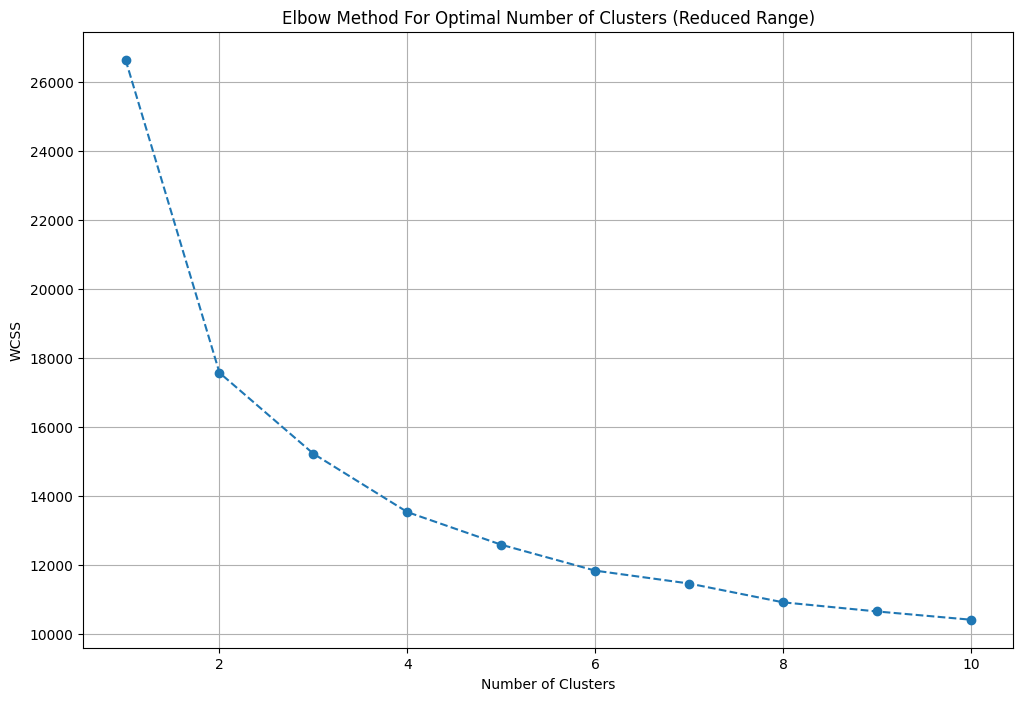

In [88]:
# Plot the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [89]:
# Assigning weights based on perceived luxury contribution
weights = {
    '24/7 Power Backup': 8,
    '24/7 Water Supply': 4,
    '24x7 Security': 7,
    'ATM': 4,
    'Aerobics Centre': 6,
    'Airy Rooms': 8,
    'Amphitheatre': 7,
    'Badminton Court': 7,
    'Banquet Hall': 8,
    'Bar/Chill-Out Lounge': 9,
    'Barbecue': 7,
    'Basketball Court': 7,
    'Billiards': 7,
    'Bowling Alley': 8,
    'Business Lounge': 9,
    'CCTV Camera Security': 8,
    'Cafeteria': 6,
    'Car Parking': 6,
    'Card Room': 6,
    'Centrally Air Conditioned': 9,
    'Changing Area': 6,
    "Children's Play Area": 7,
    'Cigar Lounge': 9,
    'Clinic': 5,
    'Club House': 9,
    'Concierge Service': 9,
    'Conference room': 8,
    'Creche/Day care': 7,
    'Cricket Pitch': 7,
    'Doctor on Call': 6,
    'Earthquake Resistant': 5,
    'Entrance Lobby': 7,
    'False Ceiling Lighting': 6,
    'Feng Shui / Vaastu Compliant': 5,
    'Fire Fighting Systems': 8,
    'Fitness Centre / GYM': 8,
    'Flower Garden': 7,
    'Food Court': 6,
    'Foosball': 5,
    'Football': 7,
    'Fountain': 7,
    'Gated Community': 7,
    'Golf Course': 10,
    'Grocery Shop': 6,
    'Gymnasium': 8,
    'High Ceiling Height': 8,
    'High Speed Elevators': 8,
    'Infinity Pool': 9,
    'Intercom Facility': 7,
    'Internal Street Lights': 6,
    'Internet/wi-fi connectivity': 7,
    'Jacuzzi': 9,
    'Jogging Track': 7,
    'Landscape Garden': 8,
    'Laundry': 6,
    'Lawn Tennis Court': 8,
    'Library': 8,
    'Lounge': 8,
    'Low Density Society': 7,
    'Maintenance Staff': 6,
    'Manicured Garden': 7,
    'Medical Centre': 5,
    'Milk Booth': 4,
    'Mini Theatre': 9,
    'Multipurpose Court': 7,
    'Multipurpose Hall': 7,
    'Natural Light': 8,
    'Natural Pond': 7,
    'Park': 8,
    'Party Lawn': 8,
    'Piped Gas': 7,
    'Pool Table': 7,
    'Power Back up Lift': 8,
    'Private Garden / Terrace': 9,
    'Property Staff': 7,
    'RO System': 7,
    'Rain Water Harvesting': 7,
    'Reading Lounge': 8,
    'Restaurant': 8,
    'Salon': 8,
    'Sauna': 9,
    'Security / Fire Alarm': 9,
    'Security Personnel': 9,
    'Separate entry for servant room': 8,
    'Sewage Treatment Plant': 6,
    'Shopping Centre': 7,
    'Skating Rink': 7,
    'Solar Lighting': 6,
    'Solar Water Heating': 7,
    'Spa': 9,
    'Spacious Interiors': 9,
    'Squash Court': 8,
    'Steam Room': 9,
    'Sun Deck': 8,
    'Swimming Pool': 8,
    'Temple': 5,
    'Theatre': 9,
    'Toddler Pool': 7,
    'Valet Parking': 9,
    'Video Door Security': 9,
    'Visitor Parking': 7,
    'Water Softener Plant': 7,
    'Water Storage': 7,
    'Water purifier': 7,
    'Yoga/Meditation Area': 7
}
# Calculate luxury score for each row
luxury_score = features_binary_df[list(weights.keys())].multiply(list(weights.values())).sum(axis=1)

In [90]:
df['luxury_score'] = luxury_score

In [91]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,features_list,luxury_score
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up area: 556 sq.ft. (51.65 sq.m.)Carpet area: 500 sq.ft. (46.45 sq.m.),2,2,2,not available,5.0,NaN,Relatively New,"['Huda City Centre', 'Golf Course Road', 'Delhi-Mumbai Expressway', 'KMP Expressway', 'Rajiv Chowk', 'IGI Airport']",[],"['Security / Fire Alarm', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",567.0,556.0,500.0,0,0,0,0,0,0,"[Security / Fire Alarm, Lift(s), Maintenance Staff, Park, Visitor Parking]",30
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,not available,8.0,West,Moderately Old,"['Sector metro station', 'Sector metro station', 'Sector 54 chowk metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'Anand Hospital Gurgaon', 'pracksht hospital', 'Arunodaya Deseret Eye Hospital', 'HUDA Office Complex', 'Medisca', 'Apollo Pharmacy', 'Intellion Park', 'International Tech Park', 'Heera Fuel Station', 'HCG CNG Station', 'Hdfc bank and atm', 'State bank of india', 'Kotak mahindra bank', 'Indusind bank', 'Axis bank', 'Icici bank', 'Hdfc bank', 'Hdfc bank & atm', 'Hdfc bank', '222', 'Pizza Hut', 'Wat-a-Burger', 'Burger Singh', 'Bikanerwala', 'Naivedyam Restaurant', 'Clock tower', 'Starbucks', ""Carl's Jr."", 'Cafe Tonini', 'Sagar Ratna', 'IILM', 'Iilm University', 'Sushant College of Arts & Architecture', 'Ansal Institute of Technology', 'Suncity School']","['1 Water Purifier', '7 Fan', '1 Exhaust Fan', '4 Geyser', '15 Light', '1 Chimney', '1 Modular Kitchen', '4 Wardrobe', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",NaN,NaN,2400.0,0,0,0,0,0,0,"[Feng Shui / Vaastu Compliant, Security / Fire Alarm, Intercom Facility, Lift(s), Maintenance Staff, Water Storage, Park, Visitor Parking]",49
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up area: 1700 sq.ft. (157.94 sq.m.)Carpet area: 1500 sq.ft. (139.35 sq.m.),3,3,3+,"pooja room,servant room",17.0,South-East,Relatively New,"['Manish Gallexie 91', 'NH-8 IMT Manesar', 'RHM Public School', 'Silver Streak Multi Speciality Hospital', 'Airport', 'Holiday Inn Gurugram']",NaN,"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Swimming Pool', 'Water Storage', 'Park', 'Visitor Parking', 'Fitness Centre / GYM', 'Club house / Community Center']",1930.0,1700.0,1500.0,1,0,1,0,0,0,"[Feng Shui / Vaastu Compliant, Security / Fire Alarm, Intercom Facility, Lift(s), Maintenance Staff, Swimming Pool, Water Storage, Park, Visitor Parking, Fitness Centre / GYM, Club house / Community Center]",65
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up area: 1900 sq.ft. (176.52 sq.m.)Carpet area: 1800 sq.ft. (167.23 sq.m.),3,3,3+,"pooja room,study room,servant room,others",7.0,South,Old Property,"['Sector metro station', 'Sector 54 chowk metro station', 'Sector metro station', 'Sanatan Dharm Mandir', 'Radhakrishna Shani Mandir', 'State bank ATM', 'Icici bank ATM', 'Icici bank ATM', 'Citi bank ATM', 'Indusind bank ATM', 'Arunodaya Deseret Eye Hospital', 'Surgicare Hospital Gurgaon', 'Kriti Hospital', 'pracksht hospital', 'Anand Hospital Gurgaon', 'HUDA Office Complex', 'Medisca', 

In [97]:
df[['property_type','nearbyLocations']].sample(5)

,property_type,nearbyLocations
1362,flat,NaN
823,flat,"['Dwarka Sector 21 Metro Station', 'HUDA Market, Sector 14', 'Ambience Mall', 'GAV Public School', 'The NorthCap University', 'Chirag Hospital', 'Indira Gandhi International Airport', 'Gurgaon Railway Station', 'DLF CyberHub', 'Fun N Food Village']"
501,flat,"['Dwarka Sector 21 Metro Station', 'Gurgaon Dreamz Mall', 'HUDA Market, Sector 14', 'Dwarka Expressway', 'Delhi Gurgaon Expressway', 'Sanskar Bharti Public School', 'The NorthCap University', 'Manipal Hospital, Gurugram', 'Indira Gandhi International Airport', 'Gurgaon Railway Station', 'The Oberoi, Gurgaon', 'Fun N Food Village', 'InfinityS Badminton Academy', 'F9 Go Karting Gurgaon', 'SCC Rooftop Drive-In']"
365,flat,"['Huda Metro Station (Gurugram)', 'Sapphire 83 Mall', 'Vatika Sector Road', 'Gurgaon - Delhi Expy', 'Dwarka Expy', 'Euro International School, Sec 84', 'DPG Degree College', 'Aarvy Healthcare Super Speciality', 'Indira Gandhi Intl Airport', 'Garhi Harsaru Junction']"
1179,flat,"['Rapid Metro Sector 56', 'M3m 65th Avenue Mall', 'Golf Course Extension Road', 'Gurgaon - Delhi Expy', 'DPS International School', 'DPG Institute of Technology', 'Park Hospital', 'Indira Gandhi International Airport', 'Lemon Tree Hotel', 'SkyJumper Trampoline Park', 'PVR Drive in Theatre']"


In [103]:
# isinstance() is a built-in Python function used to check whether a variable belongs to a particular data type (class).
type(df['nearbyLocations'].iloc[0])

str

In [105]:
import ast

df['NearbyLocationsCount'] = df['nearbyLocations'].apply(
    lambda x: len(ast.literal_eval(x)) if isinstance(x, str) else 0
)

In [106]:
df.sample(7)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,features_list,luxury_score,uniqueNearbyLocationsCount,NearbyLocationsCount
1484,flat,dlf the crest,sector 54,11.00,35222.0,3123.0,Super Built up area 3123(290.14 sq.m.),4,6,3,servant room,7.0,NaN,Relatively New,"['Sector 53-54 Metro Station', 'Ardee Mall', 'Golf Course Road', 'NH 148A', 'Sushant University', 'Shiv Nadar School', ""Lingaya's Lalita Devi Institute"", 'Paras Hospitals, Gurgaon', 'Indira Gandhi International Airport', 'Gurgaon Railway Station', 'ASF Insignia SEZ', 'DoubleTree by Hilton Hotel', 'DLF Golf and Country Club', 'Tau DeviLal Sports Complex']","['6 Fan', '1 Fridge', '1 Exhaust Fan', '5 Geyser', '1 Stove', '10 Light', '1 Chimney', '1 Modular Kitchen', '6 AC', '4 Wardrobe', '1 Microwave', '1 Washing Machine', 'No Bed', 'No Curtains', 'No Dining Table', 'No Sofa', 'No TV', 'No Water Purifier']","['Security / Fire Alarm', 'Power Back-up', 'Intercom Facility', 'Lift(s)', 'Centrally Air Conditioned', 'Maintenance Staff', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Low Density Society', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']",3123.0,NaN,NaN,0,0,1,0,0,1,"[Security / Fire Alarm, Power Back-up, Intercom Facility, Lift(s), Centrally Air Conditioned, Maintenance Staff, Water Storage, Separate entry for servant room, No open drainage around, Piped-gas, Visitor Parking, Swimming Pool, Park, Security Personnel, Natural Light, Airy Rooms, Spacious Interiors, Low Density Society, Fitness Centre / GYM, Waste Disposal, Rain Water Harvesting, Club house / Community Center]",125,0,14
1713,flat,puri diplomatic greens,sector 111,3.40,11525.0,2950.0,Super Built up area 2950(274.06 sq.m.),4,5,3+,servant room,14.0,East,Relatively New,"['Dwarka Sector 21 Metro Station', 'Gurgaon Dreamz Mall', 'Dwarka Expressway', 'Delhi', 'Delhi Jaipur Highway', 'Red Roses Public School', 'The NorthCap University', 'Metro Hospital, Palam Vihar', 'Indira Gandhi International Airport', 'The Oberoi, Gurgaon']","['1 Stove', '5 AC', '1 Modular Kitchen', '1 Chimney', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Light', 'No Microwave', 'No Fridge', 'No Sofa', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'Water Storage', 'No open drainage around', 'Bank Attached Property', 'Visitor Parking', 'Swimming Pool', 'Park', 'Internet/wi-fi connectivity', 'Low Density Society', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']",2950.0,NaN,NaN,0,0,1,0,0,0,"[Security / Fire Alarm, Feng Shui / Vaastu Compliant, Intercom Facility, Lift(s), High Ceiling Height, Maintenance Staff, Water Storage, No open drainage around, Bank Attached Property, Visitor Parking, Swimming Pool, Park, Internet/wi-fi connectivity, Low Density Society, Fitness Centre / GYM, Waste Disposal, Rain Water Harvesting, Club house / Community Center]",94,0,10
1675,flat,smart world orchard,sector 61,1.55,13478.0,1150.0,Super Built up area 1150(106.84 sq.m.),2,2,1,study room,3.0,NaN,Under Construction,"['Sector 55-56 Metro station', 'Bestech Central Square Mall', 'Golf Course Ext Road', 'Badshahpur Sohna Rd Hwy', 'ORCHIDS The International School', 'Sushant University', 'Marengo Asia Hospitals', 'Indira Gandhi Intl Airport', 'Gurgaon Railway Station']","['3 Fan', '1 Exhaust Fan', '4 Light', '3 AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Di

In [107]:
# cols to drop -> nearbyLocations,furnishDetails, features,features_list, additionalRoom
df.drop(columns=['nearbyLocations','furnishDetails','features','features_list','additionalRoom','uniqueNearbyLocationsCount'],inplace=True)

In [108]:
df.sample(5)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
1790,flat,krrish florence estate,sector 70,1.30,5600.0,2321.0,Built Up area: 1865 (173.26 sq.m.),3,3,3,17.0,NaN,Under Construction,NaN,1865.0,NaN,0,0,0,0,0,0,61,7
1832,house,unitech uniworld resorts,sector 33,8.00,17778.0,4500.0,Built Up area: 500 (418.06 sq.m.),6,5,3+,4.0,NaN,Undefined,NaN,500.0,NaN,0,0,0,0,0,0,0,0
3282,flat,shapoorji pallonji joyville gurugram,sector 102,1.77,9195.0,1925.0,Super Built up area 1827(169.73 sq.m.),3,3,3,1.0,North-East,Relatively New,1827.0,NaN,NaN,0,0,0,0,0,0,151,13
1306,house,tulip yellow,sector 69,2.95,16389.0,1800.0,Plot area 200(167.23 sq.m.),4,3,2,3.0,North,New Property,NaN,1800.0,NaN,1,0,0,0,1,1,111,13
2934,flat,tulip violet,sector 69,1.76,9513.0,1850.0,Super Built up area 1850(171.87 sq.m.),3,4,2,0.0,South-West,Relatively New,1850.0,NaN,NaN,0,0,0,0,0,0,157,10


In [109]:
df.shape

(3799, 24)

In [110]:
df.to_csv('merged_cleaned_FE_data_v2.csv',index=False)